11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


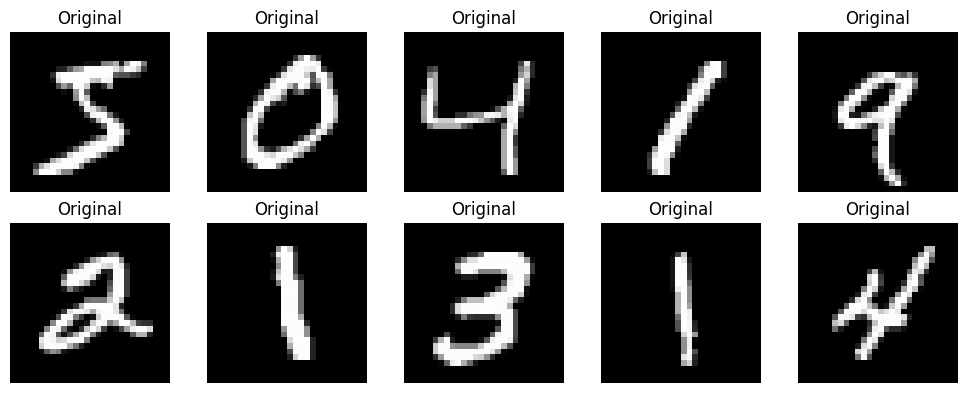

Training data shape after flattening: (60000, 784)
Testing data shape after flattening: (10000, 784)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - loss: 0.4097 - val_loss: 0.2699
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.2661 - val_loss: 0.2640
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.2638 - val_loss: 0.2632
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.2633 - val_loss: 0.2629
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.2631 - val_loss: 0.2627
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.2630 - val_loss: 0.2627
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - loss: 0.2630 - val_loss: 0.2627
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - loss: 0.2630 - val_loss: 0.2627
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.2629 - val_loss: 0.2626
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.2629 - val_loss: 0.2626
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.2629 - val_loss: 0.2627
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 

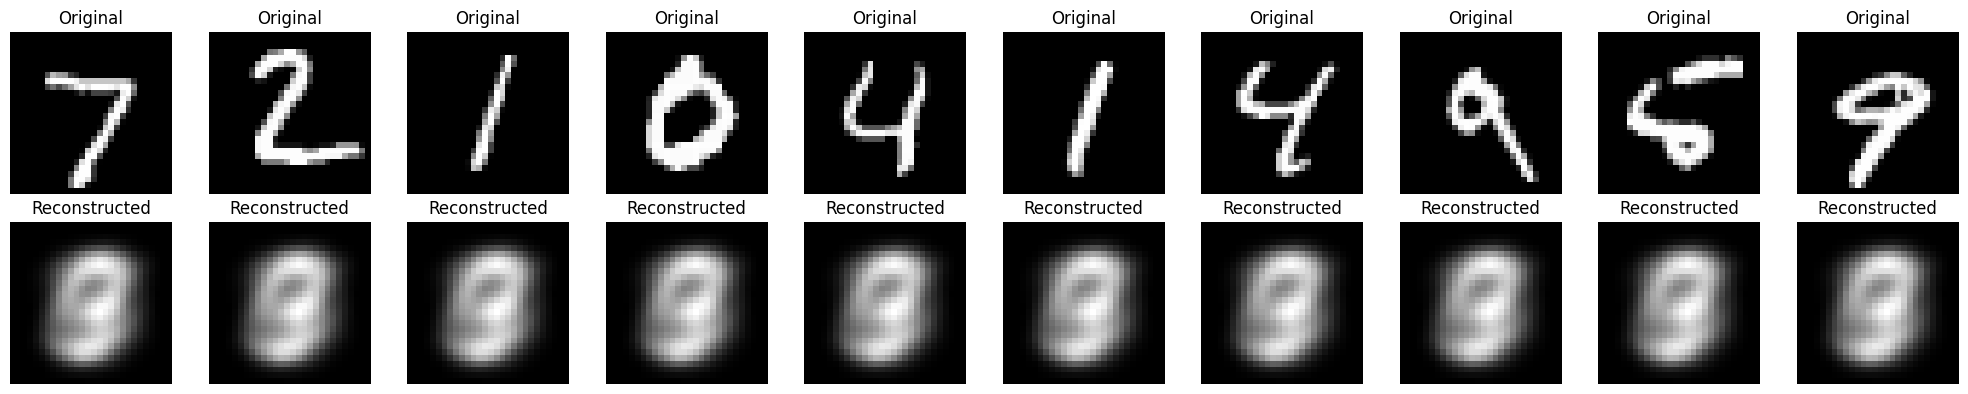

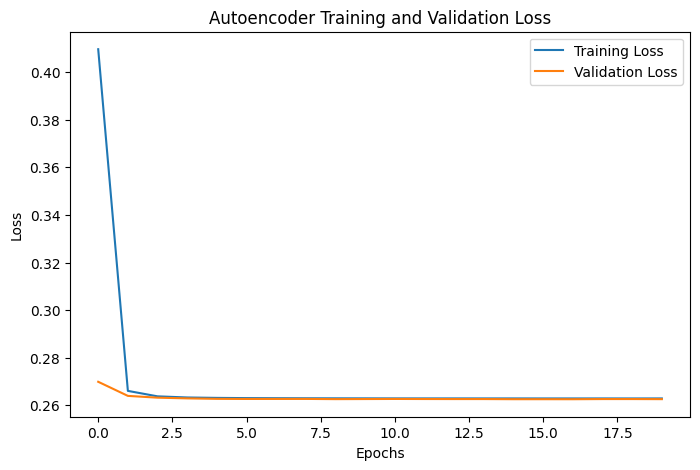

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Encoded representation shape: (10000, 32)


In [1]:

# STEP 1: Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

# STEP 2: Load MNIST dataset

(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# STEP 3: Display first 10 original images

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")
    plt.title("Original")

plt.tight_layout()
plt.show()

# STEP 4: Normalize the images

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# STEP 5: Flatten the images

x_train = x_train.reshape((len(x_train), 784))
x_test = x_test.reshape((len(x_test), 784))

print("Training data shape after flattening:", x_train.shape)
print("Testing data shape after flattening:", x_test.shape)

# STEP 6: Define the encoder

input_layer = keras.Input(shape=(784,))

encoded = layers.Dense(128, activation="relu")(input_layer)

encoded_output = layers.Dense(
    32,
    activation="relu",
    activity_regularizer=regularizers.L1(0.0001)
)(encoded)

# STEP 7: Define the decoder

decoded = layers.Dense(128, activation="relu")(encoded_output)

output_layer = layers.Dense(784, activation="sigmoid")(decoded)

# STEP 8: Create the autoencoder model

autoencoder = keras.Model(input_layer, output_layer)

# STEP 9: Compile the model

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

# STEP 10: Display model architecture

autoencoder.summary()

# STEP 11: Train the autoencoder

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# STEP 12: Reconstruct the test images

reconstructed_images = autoencoder.predict(x_test)

print("Original test data shape:", x_test.shape)
print("Reconstructed data shape:", reconstructed_images.shape)

# STEP 13: Display original and reconstructed images

n = 10

plt.figure(figsize=(20, 4))

for i in range(n):

    # Original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

# STEP 14: Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# STEP 15: Create encoder model to view encoded representations

encoder = keras.Model(input_layer, encoded_output)

encoded_images = encoder.predict(x_test)

print("Encoded representation shape:", encoded_images.shape)
